In [10]:
import matplotlib.pyplot as plt
import geopandas as gp
import regionmask
import cartopy
import cartopy.crs as ccrs

## Broadacre Regions

In [2]:
broadacre_gdf = gp.read_file('shapefiles/aagis_asgs16v1_g5a.shp')

In [3]:
broadacre_gdf

,aagis,class,name,zone,geometry
0,111,111,NSW Far West,Pastoral,"POLYGON ((146.37539 -28.99878, 146.94501 -28.9..."
1,121,121,NSW North West Slopes and Plains,Wheat Sheep,"POLYGON ((150.29716 -28.54252, 150.29783 -28.5..."
2,122,122,NSW Central West,Wheat Sheep,"POLYGON ((149.02819 -30.6089, 149.05246 -30.63..."
3,123,123,NSW Riverina,Wheat Sheep,"POLYGON ((145.34428 -32.68249, 145.33056 -32.7..."
4,131,131,NSW Tablelands (Northern Central and Southern),High Rainfall,"POLYGON ((152.51672 -28.25466, 152.5161 -28.25..."
5,132,132,NSW Coastal,High Rainfall,"MULTIPOLYGON (((150.05118 -37.26355, 150.05099..."
6,221,221,VIC Mallee,Wheat Sheep,"POLYGON ((140.96768 -33.98983, 140.96827 -33.9..."
7,222,222,VIC Wimmera,Wheat Sheep,"POLYGON ((141.99493 -35.645, 141.99495 -35.653..."
8,223,223,VIC Central North,Wheat Sheep,"POLYGON ((145.5341 -35.80522, 145.5339 -35.806..."
9,231,231,VIC Southern and Eastern Victoria,High Rainfall,"MULTIPOLYGON (((146.29518 -39.15886, 146.29331..."


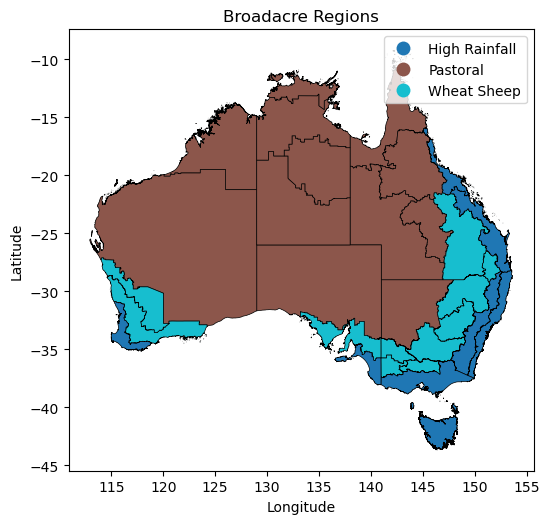

In [4]:
broadacre_gdf.plot(
    figsize=[6, 6],
    column='zone',
    legend=True,
    linewidth=0.5,
    edgecolor='black',
)
plt.title('Broadacre Regions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
wheatbelt_gdf = broadacre_gdf[broadacre_gdf.zone == 'Wheat Sheep']
wheatbelt = wheatbelt_gdf.dissolve()
wheatbelt = wheatbelt.drop(columns=['aagis', 'class', 'name'])

wheatbelt_region = regionmask.from_geopandas(
    wheatbelt,
    names="zone",
    name="wheatbelt"
)

## NCRA regions

Dowloaded from https://doi.org/10.25919/8tqq-0007

In [21]:
def plot_region(shapefile):
    """Plot a shapefile region"""

    gdf = gp.read_file(shapefile)
    fig = plt.figure(figsize=[7, 5])
    ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    ax.add_geometries(gdf.geometry, ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cartopy.feature.STATES)
    ax.gridlines(linestyle="--", draw_labels=True)
    ax.set_extent([113, 154, -44, -10], crs=ccrs.PlateCarree())
    ax.set_title(gdf['region'][0])
    plt.show()

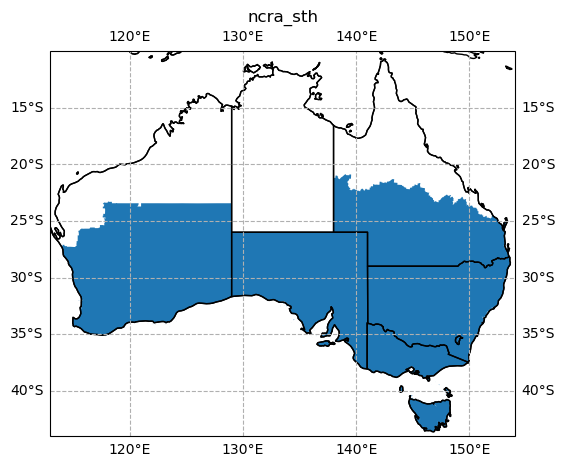

In [22]:
plot_region('shapefiles/ncra_sth_shp_processed.shp')

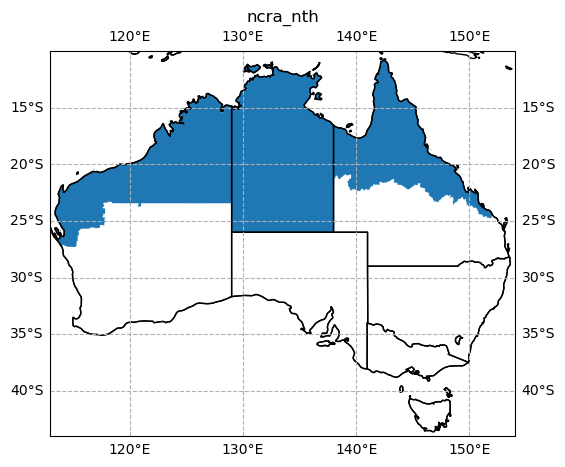

In [23]:
plot_region('shapefiles/ncra_nth_shp_processed.shp')

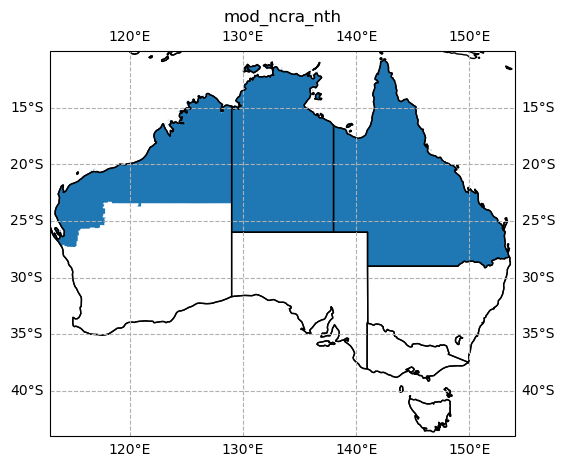

In [25]:
plot_region('shapefiles/mod_ncra_nth_shp_processed.shp')

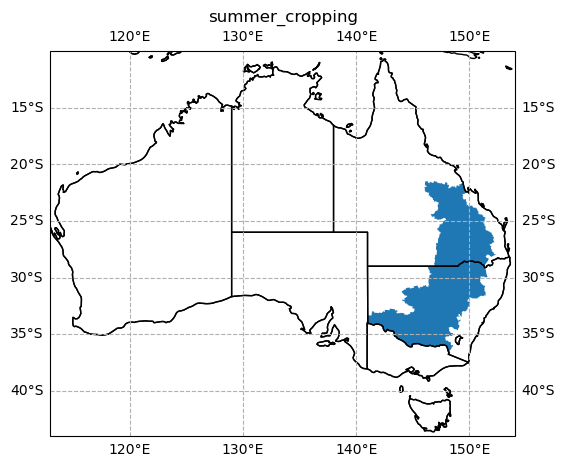

In [26]:
plot_region('shapefiles/summer_cropping_shp_processed.shp')

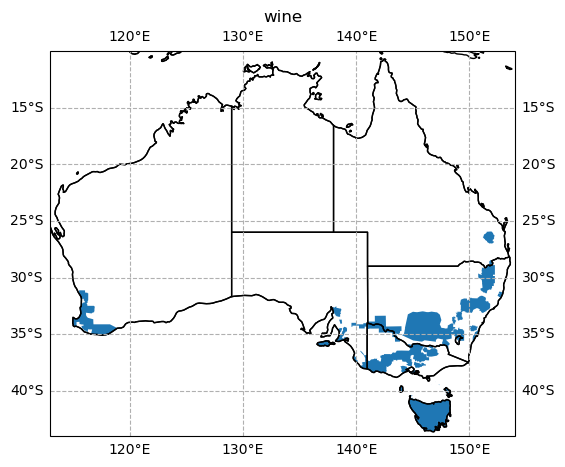

In [28]:
plot_region('shapefiles/wine_shp_processed.shp')

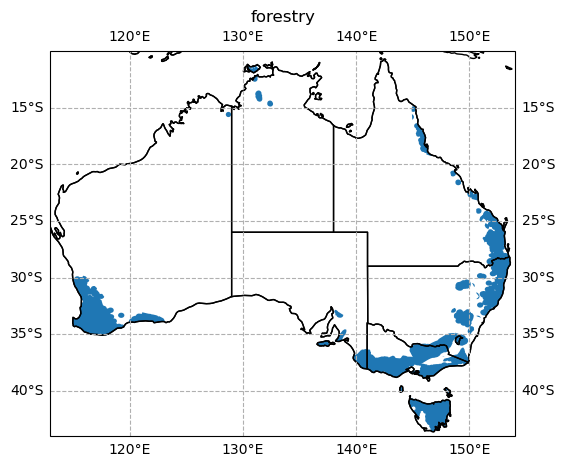

In [24]:
plot_region('shapefiles/forestry_shp_processed.shp')